<a href="https://colab.research.google.com/github/KevinT135/DS3001-Final-Project/blob/main/Decision_Tree_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== 1. DATA CLEANING SUMMARY ===
May 2015 Commerical Custoomers: 200,600 -> interpolated to 448,066
Dropped 8 Preliminary rows (2026). Final dataset: 192 months (2010-2025)



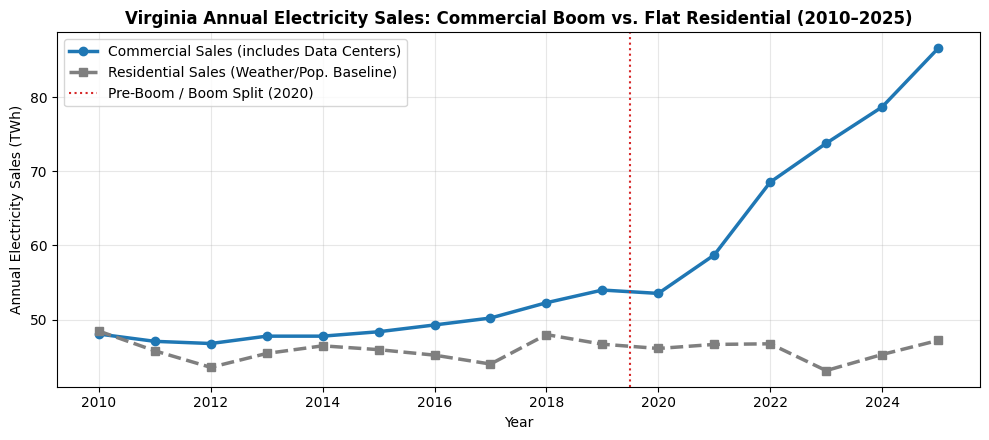

=== 2. STEP 1: FIT TEST & STOPPING RULE COMPARISON (5-Fold CV, 2010–2025) ===
Unconstrained Tree                 | Leaves: 192 | Train RMSE:         0 | CV RMSE:   453,295 | CV R^2: 0.8235
Interpretable (depth=3, leaf=5)    | Leaves:   8 | Train RMSE:   354,136 | CV RMSE:   453,958 | CV R^2: 0.8275
Tuned (depth=10, leaf=3)           | Leaves:  57 | Train RMSE:   180,273 | CV RMSE:   397,533 | CV R^2: 0.8645
5-Seed Stability (Tuned Tree):     | CV RMSE: 395,526 +/- 24,115 MWh | CV R^2: 0.8678 +/- 0.0174

=== PLAIN-TEXT TREE RULES (max_depth=3, min_samples_leaf=5) ===
|--- month_counter <= 146.50
|   |--- month_counter <= 99.50
|   |   |--- RESIDENTIAL_Sales_Megawatthours <= 3681039.25
|   |   |   |--- value: [3833134.76]
|   |   |--- RESIDENTIAL_Sales_Megawatthours >  3681039.25
|   |   |   |--- value: [4176977.84]
|   |--- month_counter >  99.50
|   |   |--- month_counter <= 136.50
|   |   |   |--- value: [4493308.09]
|   |   |--- month_counter >  136.50
|   |   |   |--- value: [519866

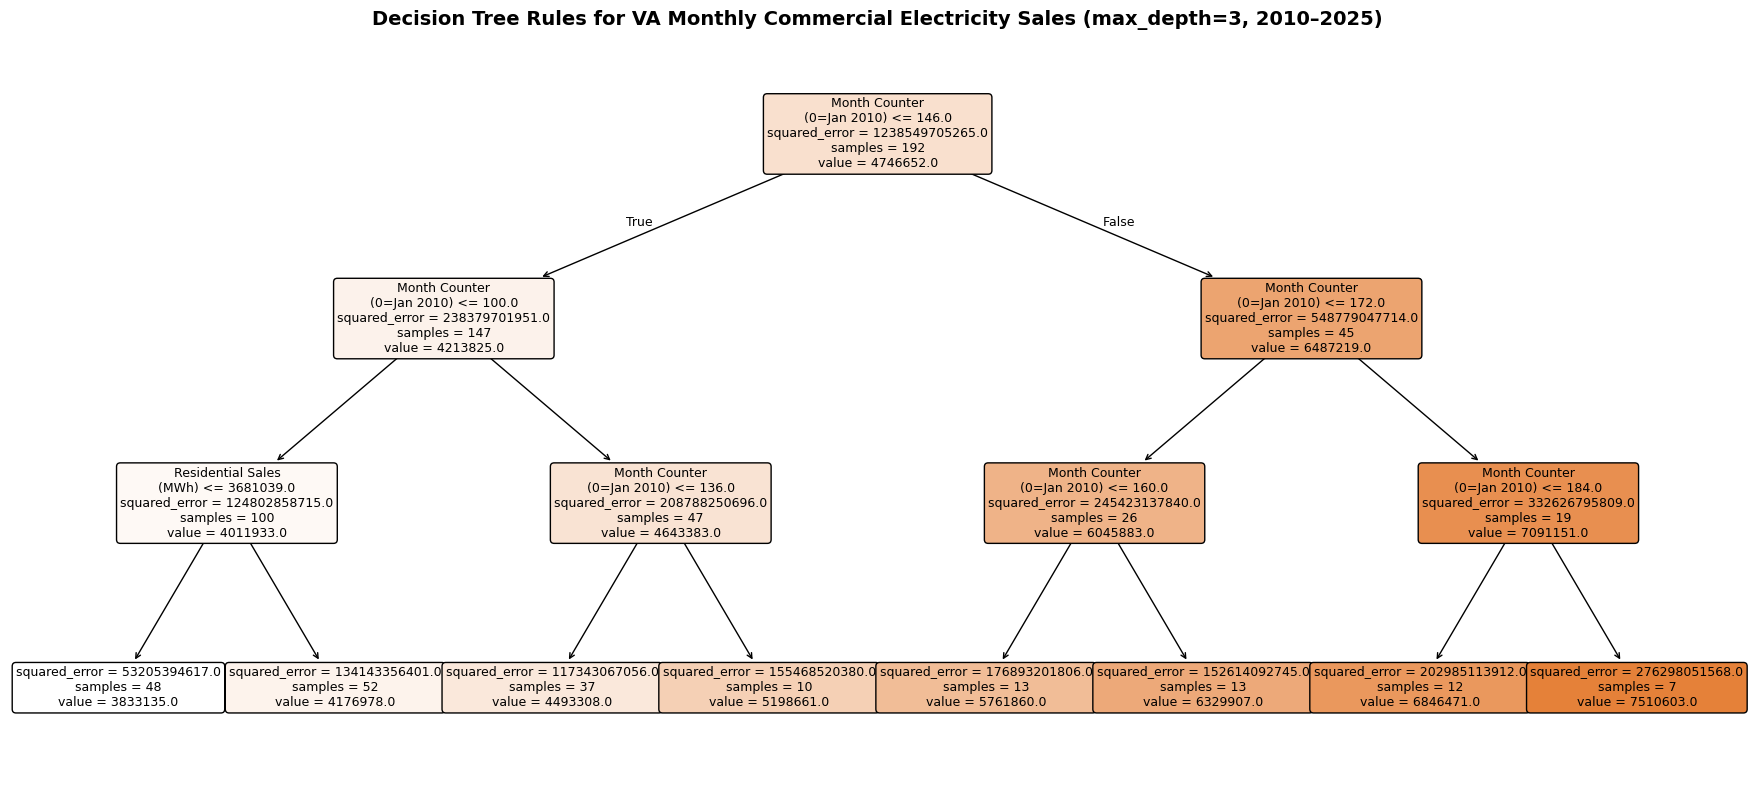

=== 3. STEP 2: STRAIN TEST (Train 2010–2019, Predict 2020–2025) ===
DT Best Params (2010–2019):   {'max_depth': 6, 'min_samples_leaf': 5}
DT Train CV RMSE (2010–2019): 227,229 MWh
DT Test RMSE (2020–2025):     1,692,353 MWh | R^2: -1.4787
DT Extrapolation Cap:         Max Predicted = 4,809,575 MWh vs. Max Actual = 8,462,206 MWh
Ridge Test RMSE (2020–2025):  1,570,089 MWh | R^2: -1.1335

      Actual_TWh  DT_Pred_TWh  DT_Gap_TWh  Ridge_Pred_TWh  Ridge_Gap_TWh  \
Year                                                                       
2020       53.53        53.74       -0.22           52.93           0.60   
2021       58.72        53.74        4.98           53.75           4.97   
2022       68.56        53.74       14.81           54.45          14.10   
2023       73.81        53.74       20.06           54.17          19.64   
2024       78.71        53.74       24.97           55.43          23.28   
2025       86.62        53.74       32.88           56.62          30.01   

 

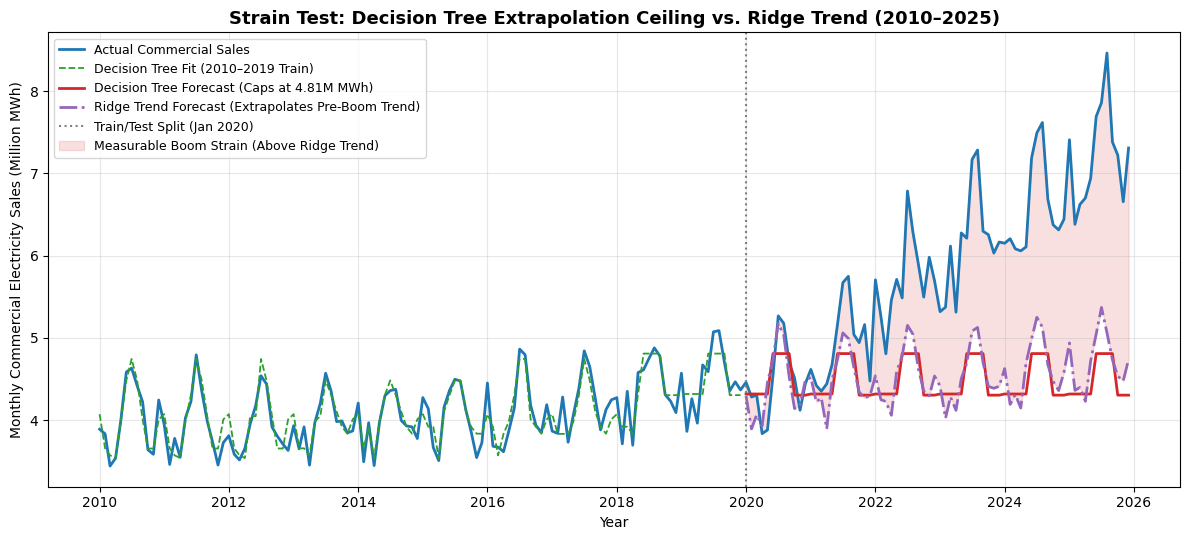

=== 4. VIRGINIA POWER DENSITY -> TEXAS & GEORGIA PROJECTION ===
VA Imputed Data Center Sqft: 46,403,387 sqft
Empirical Power Density:     73.8 W/sqft (Ridge) | 80.9 W/sqft (Decision Tree)

           DC_Counties  Total_Sqft  Est_Load_MW_Ridge  Est_Load_MW_DT  \
state_abb                                                               
GA                   8   7984893.1              589.5           645.9   
TX                  16  22966688.6             1695.4          1857.7   

           Local_Summer_MW  Deficit_Counties  
state_abb                                     
GA                  2827.2                 5  
TX                 28309.9                 1  


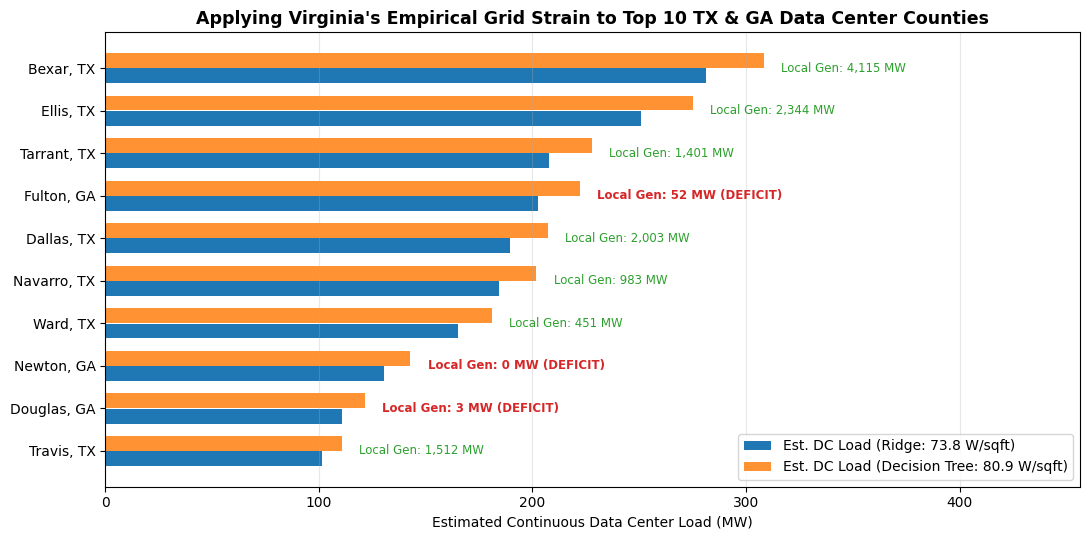

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.metrics import root_mean_squared_error, r2_score

df = pd.read_csv('/content/sales_va_monthly.csv')

mask_may2015 = (df['Year'] == 2015) & (df['Month'] == 5)
raw_may2015 = df.loc[mask_may2015, 'COMMERCIAL_Customers_Count'].values[0]
df.loc[mask_may2015, 'COMMERCIAL_Customers_Count'] = np.nan
df['COMMERCIAL_Customers_Count'] = df['COMMERCIAL_Customers_Count'].interpolate()
fixed_may2015 = df.loc[mask_may2015, 'COMMERCIAL_Customers_Count'].values[0]

n_prelim = df['Preliminary'].sum()
df_clean = df[df['Preliminary'] == False].copy().reset_index(drop=True)
df_clean['Date_dt'] = pd.to_datetime(df_clean['Date'])

df_clean['month_counter'] = (df_clean['Year'] - 2010) * 12 + (df_clean['Month'] - 1)
features = ['month_counter', 'Month', 'RESIDENTIAL_Sales_Megawatthours']
target = 'COMMERCIAL_Sales_Megawatthours'

X = df_clean[features]
y = df_clean[target]

print("=== 1. DATA CLEANING SUMMARY ===")
print(f"May 2015 Commerical Custoomers: {raw_may2015:,.0f} -> interpolated to {fixed_may2015:,.0f}")
print(f"Dropped {n_prelim} Preliminary rows (2026). Final dataset: {len(df_clean)} months ({df_clean['Year'].min()}-{df_clean['Year'].max()})\n")

annual_totals = df_clean.groupby('Year')[
    ['COMMERCIAL_Sales_Megawatthours', 'RESIDENTIAL_Sales_Megawatthours']
].sum() / 1e6  # Convert MWh to TWh

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(annual_totals.index, annual_totals['COMMERCIAL_Sales_Megawatthours'],
        marker='o', linewidth=2.5, color='#1f77b4', label='Commercial Sales (includes Data Centers)')
ax.plot(annual_totals.index, annual_totals['RESIDENTIAL_Sales_Megawatthours'],
        marker='s', linewidth=2.5, color='#7f7f7f', linestyle='--', label='Residential Sales (Weather/Pop. Baseline)')
ax.axvline(2019.5, color='#d62728', linestyle=':', linewidth=1.5, label='Pre-Boom / Boom Split (2020)')
ax.set_title('Virginia Annual Electricity Sales: Commercial Boom vs. Flat Residential (2010–2025)', fontsize=12, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Annual Electricity Sales (TWh)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig1_va_commercial_vs_residential.png', dpi=150)
plt.show()

# ==============================================================================
# SECTION 2: STEP 1 — FIT TEST (5-Fold Cross-Validation, 2010–2025)
# ==============================================================================
cv = KFold(n_splits=5, shuffle=True, random_state=100)
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_leaf': [1, 2, 3, 5, 7, 10, 15]
}

grid_fit = GridSearchCV(
    DecisionTreeRegressor(random_state=100),
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)
grid_fit.fit(X, y)
best_fit_tree = grid_fit.best_estimator_

# Compare stopping rules (Unconstrained vs. Interpretable vs. Tuned)
comparison_models = {
    'Unconstrained Tree': DecisionTreeRegressor(random_state=100),
    'Interpretable (depth=3, leaf=5)': DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=100),
    f"Tuned (depth={grid_fit.best_params_['max_depth']}, leaf={grid_fit.best_params_['min_samples_leaf']})": best_fit_tree
}

print("=== 2. STEP 1: FIT TEST & STOPPING RULE COMPARISON (5-Fold CV, 2010–2025) ===")
for name, m in comparison_models.items():
    cv_rmse = -cross_val_score(m, X, y, cv=cv, scoring='neg_root_mean_squared_error').mean()
    cv_r2 = cross_val_score(m, X, y, cv=cv, scoring='r2').mean()
    m.fit(X, y)
    tr_rmse = root_mean_squared_error(y, m.predict(X))
    print(f"{name:34s} | Leaves: {m.get_n_leaves():3d} | Train RMSE: {tr_rmse:9,.0f} | CV RMSE: {cv_rmse:9,.0f} | CV R^2: {cv_r2:.4f}")

# Stability check across 5 random CV seeds
seed_rmses, seed_r2s = [], []
for seed in [42, 100, 104, 2025, 3001]:
    cv_s = KFold(n_splits=5, shuffle=True, random_state=seed)
    m_s = DecisionTreeRegressor(**grid_fit.best_params_, random_state=100)
    seed_rmses.append(-cross_val_score(m_s, X, y, cv=cv_s, scoring='neg_root_mean_squared_error').mean())
    seed_r2s.append(cross_val_score(m_s, X, y, cv=cv_s, scoring='r2').mean())
print(f"5-Seed Stability (Tuned Tree):     | CV RMSE: {np.mean(seed_rmses):,.0f} +/- {np.std(seed_rmses):,.0f} MWh | CV R^2: {np.mean(seed_r2s):.4f} +/- {np.std(seed_r2s):.4f}\n")

# Figure 2: Qualitative Output — Readable Decision Tree (max_depth=3) + Rules
interp_tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=100).fit(X, y)
print("=== PLAIN-TEXT TREE RULES (max_depth=3, min_samples_leaf=5) ===")
print(export_text(interp_tree, feature_names=features))

fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    interp_tree,
    feature_names=['Month Counter\n(0=Jan 2010)', 'Month of Year', 'Residential Sales\n(MWh)'],
    filled=True, rounded=True, fontsize=9, precision=0, ax=ax
)
ax.set_title('Decision Tree Rules for VA Monthly Commercial Electricity Sales (max_depth=3, 2010–2025)', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('fig2_decision_tree_rules.png', dpi=150)
plt.show()

# ==============================================================================
# SECTION 3: STEP 2 — STRAIN TEST (Train 2010–2019, Predict 2020–2025)
# ==============================================================================
train_df = df_clean[df_clean['Year'] <= 2019].copy()
test_df = df_clean[df_clean['Year'] >= 2020].copy()

X_train, y_train = train_df[features], train_df[target]
X_test, y_test = test_df[features], test_df[target]

# Tune Decision Tree strictly on 2010–2019
grid_strain = GridSearchCV(
    DecisionTreeRegressor(random_state=100),
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)
grid_strain.fit(X_train, y_train)
best_strain_dt = grid_strain.best_estimator_

train_df['dt_pred'] = best_strain_dt.predict(X_train)
test_df['dt_pred'] = best_strain_dt.predict(X_test)

# Ridge Regression benchmark (same 3 features, Month one-hot encoded) for comparison
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), ['month_counter', 'RESIDENTIAL_Sales_Megawatthours']),
    ('cat', OneHotEncoder(drop='first'), ['Month'])
])
ridge_pipe = Pipeline([('pre', preprocessor), ('ridge', Ridge())])
ridge_grid = GridSearchCV(
    ridge_pipe,
    param_grid={'ridge__alpha': [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]},
    cv=cv,
    scoring='neg_root_mean_squared_error'
)
ridge_grid.fit(X_train, y_train)
test_df['ridge_pred'] = ridge_grid.predict(X_test)

print("=== 3. STEP 2: STRAIN TEST (Train 2010–2019, Predict 2020–2025) ===")
print(f"DT Best Params (2010–2019):   {grid_strain.best_params_}")
print(f"DT Train CV RMSE (2010–2019): {-grid_strain.best_score_:,.0f} MWh")
print(f"DT Test RMSE (2020–2025):     {root_mean_squared_error(y_test, test_df['dt_pred']):,.0f} MWh | R^2: {r2_score(y_test, test_df['dt_pred']):.4f}")
print(f"DT Extrapolation Cap:         Max Predicted = {test_df['dt_pred'].max():,.0f} MWh vs. Max Actual = {y_test.max():,.0f} MWh")
print(f"Ridge Test RMSE (2020–2025):  {root_mean_squared_error(y_test, test_df['ridge_pred']):,.0f} MWh | R^2: {r2_score(y_test, test_df['ridge_pred']):.4f}\n")

# Annual Strain Gap Table (TWh and continuous GW)
test_df['dt_gap'] = test_df[target] - test_df['dt_pred']
test_df['ridge_gap'] = test_df[target] - test_df['ridge_pred']

annual_strain = test_df.groupby('Year').agg(
    Actual_TWh=(target, lambda s: s.sum() / 1e6),
    DT_Pred_TWh=('dt_pred', lambda s: s.sum() / 1e6),
    DT_Gap_TWh=('dt_gap', lambda s: s.sum() / 1e6),
    Ridge_Pred_TWh=('ridge_pred', lambda s: s.sum() / 1e6),
    Ridge_Gap_TWh=('ridge_gap', lambda s: s.sum() / 1e6)
)
annual_strain['DT_Gap_GW'] = (annual_strain['DT_Gap_TWh'] * 1000) / 8760
annual_strain['Ridge_Gap_GW'] = (annual_strain['Ridge_Gap_TWh'] * 1000) / 8760
print(annual_strain.round(2))
print()

# Figure 3: Strain Test — Decision Tree Ceiling vs. Ridge Trend
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(df_clean['Date_dt'], df_clean[target] / 1e6, color='#1f77b4', linewidth=2, label='Actual Commercial Sales')
ax.plot(train_df['Date_dt'], train_df['dt_pred'] / 1e6, color='#2ca02c', linestyle='--', linewidth=1.3, label='Decision Tree Fit (2010–2019 Train)')
ax.plot(test_df['Date_dt'], test_df['dt_pred'] / 1e6, color='#d62728', linewidth=2, label='Decision Tree Forecast (Caps at 4.81M MWh)')
ax.plot(test_df['Date_dt'], test_df['ridge_pred'] / 1e6, color='#9467bd', linestyle='-.', linewidth=2, label='Ridge Trend Forecast (Extrapolates Pre-Boom Trend)')
ax.axvline(pd.Timestamp('2020-01-01'), color='gray', linestyle=':', linewidth=1.5, label='Train/Test Split (Jan 2020)')
ax.fill_between(test_df['Date_dt'], test_df['ridge_pred'] / 1e6, test_df[target] / 1e6, color='#d62728', alpha=0.14, label='Measurable Boom Strain (Above Ridge Trend)')
ax.set_title('Strain Test: Decision Tree Extrapolation Ceiling vs. Ridge Trend (2010–2025)', fontsize=13, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Monthly Commercial Electricity Sales (Million MWh)')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig3_strain_test_dt_vs_ridge.png', dpi=150)
plt.show()

# ==============================================================================
# SECTION 4: APPLYING VIRGINIA'S STRAIN TO TEXAS & GEORGIA
# ==============================================================================
dc = pd.read_csv('/content/county_level_dc_eia_merged.csv')
va_sqft = dc.loc[dc['state_abb'] == 'VA', 'total_sqft_imputed'].sum()

dt_gw_2025 = annual_strain.loc[2025, 'DT_Gap_GW']
ridge_gw_2025 = annual_strain.loc[2025, 'Ridge_Gap_GW']

w_per_sqft_dt = (dt_gw_2025 * 1e9) / va_sqft        # ~80.9 W/sqft
w_per_sqft_ridge = (ridge_gw_2025 * 1e9) / va_sqft  # ~73.8 W/sqft

tx_ga = dc[dc['state_abb'].isin(['TX', 'GA'])].copy()
tx_ga['est_load_mw_ridge'] = (tx_ga['total_sqft_imputed'] * w_per_sqft_ridge) / 1e6
tx_ga['est_load_mw_dt'] = (tx_ga['total_sqft_imputed'] * w_per_sqft_dt) / 1e6
tx_ga['exceeds_local_gen'] = tx_ga['est_load_mw_ridge'] > tx_ga['operable_summer_mw']

print("=== 4. VIRGINIA POWER DENSITY -> TEXAS & GEORGIA PROJECTION ===")
print(f"VA Imputed Data Center Sqft: {va_sqft:,.0f} sqft")
print(f"Empirical Power Density:     {w_per_sqft_ridge:.1f} W/sqft (Ridge) | {w_per_sqft_dt:.1f} W/sqft (Decision Tree)\n")
print(tx_ga.groupby('state_abb').agg(
    DC_Counties=('county', 'count'),
    Total_Sqft=('total_sqft_imputed', 'sum'),
    Est_Load_MW_Ridge=('est_load_mw_ridge', 'sum'),
    Est_Load_MW_DT=('est_load_mw_dt', 'sum'),
    Local_Summer_MW=('operable_summer_mw', 'sum'),
    Deficit_Counties=('exceeds_local_gen', 'sum')
).round(1))

# Figure 4: Top 10 TX & GA Counties — Projected Load vs. Local Operable Generation
top10 = tx_ga.sort_values('est_load_mw_ridge', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(11, 5.5))
labels = [f"{r['county'].replace(' County', '')}, {r['state_abb']}" for _, r in top10.iterrows()][::-1]
y_pos = np.arange(len(labels))
ridge_vals = top10['est_load_mw_ridge'].values[::-1]
dt_vals = top10['est_load_mw_dt'].values[::-1]
gen_vals = top10['operable_summer_mw'].values[::-1]

ax.barh(y_pos - 0.18, ridge_vals, height=0.35, label=f'Est. DC Load (Ridge: {w_per_sqft_ridge:.1f} W/sqft)', color='#1f77b4')
ax.barh(y_pos + 0.18, dt_vals, height=0.35, label=f'Est. DC Load (Decision Tree: {w_per_sqft_dt:.1f} W/sqft)', color='#ff7f0e', alpha=0.85)

for i, (r_val, g_val) in enumerate(zip(ridge_vals, gen_vals)):
    status = f"Local Gen: {g_val:,.0f} MW" + (" (DEFICIT)" if g_val < r_val else "")
    color = '#d62728' if g_val < r_val else '#2ca02c'
    ax.text(max(r_val, dt_vals[i]) + 8, i, status, va='center', fontsize=8.5,
            color=color, fontweight='bold' if g_val < r_val else 'normal')

ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.set_xlabel('Estimated Continuous Data Center Load (MW)')
ax.set_title("Applying Virginia's Empirical Grid Strain to Top 10 TX & GA Data Center Counties", fontsize=12.5, fontweight='bold')
ax.set_xlim(0, max(dt_vals) * 1.48)
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('fig4_tx_ga_county_load_projection.png', dpi=150)
plt.show()

Data Cleaning and Why it Matters:
- Scope: We use EIA monthly electricity sales for Virginia (sales_va_monthly.csv). After removing the 8 primilary 2026 rows (Preliminary == True), our clean modeling dataset covers 192 complete months from January 2010 to December 2025.
 - Anomaly Fix: May 2015 had a clear reporting glitch in COMMERCIAL_Customers_Count (200,600 vs. 448,000 in adjacent months), which we fixed via linear interpolation (448,066) so the team shares one clean dataset.

- Why Commercial vs Residential Is the Smoking Gun: In EIA utility billing, data centers are classified under the commercial sector. Between 2010 and 2025, Virginia's residential sales stayed flat (48.44 TWh -> 47.17 TWh), ruling out population growth or hotter weather as the cause. Over the same span, commericla sales surged +80.3% (48.04 TWh -> 86.62 TWh), with the sharpest acceleration starting after 2020.

Step 1 - Fit Test & Tree Interpretability:
- Shared Features: All four models use month_counter (long-term trend), Month (seasonality), and RESIDENTIAL_sales_Megawatthours (weather proxy) to predict COMMERCIAL_Sales_Megawatthours.
- Regularization Matters: Using 5-fold cross validation across 2010-2025, an unconstrained Decision Tree memorizes every single month (192 leaves, Train RMSE = 0, CV RMSE = 453,295 MWh, R^2 = 0.8235). Tuning max_depth and min_samples_leaf via GridSearchCV selectcs max_depth = 10, min_samples_leaf = 3 (57 leaves), cutting CV RMSE to 397,533 MWh and lifting CV R^2 to 0.8645
- Stability Check: Following Lecture A06, we verified that this isn't lucky split by re-running 5-fold CV across 5 different random seeds (42, 100, 104, 2025, 3001), getting a consistent 395, 526+-24,115 MWh RMSE (R^2 = 0.8678 +- 0.0174).
- What the Plotted Tree (max_depth = 3) Tells Us: In the readable 8-leaf tree, time (month_counter) drives almost every split. Weather (Residential Sales) only matters before April 2018 (month_counter <= 99.5), splitting mild months (3.83M MWh) from peak-weather months (4.18M MWh). After 2021, commericla demand climbs in rapid, distinct steps - from 5.20M MWh/month (2021-2022) to 7.51M MWh/month (late 2025) - showing that baseload data center growth has completely drowned out normal weather variation.

Step 2 - Strain and Why Trees Fail to Extrapolate
- The experiment: We train strictly on 2010-2019 (pre-boom) and predict 2020-2025. Tuning on 2010-2019 selects max_depth=6, min_samples_leaf = 5 (Train CV RMSE = 227,229 MWh)
- The Result: On 2020 - 2025, the Decision Tree's error explodes to RMSE = 1,692,353 MWh (R^2 = -1.4787). In 2025 alone, actual commercial sales hit 86.62 TWh, while the tree predicted 53.74 TWh - a gap of 32.88 TWh (3.75 GW continuous).
- The Key Methodological Lesson ("Why Some Models Don't Work Well"): A decision Tree predicts the average of teh training samples in each leaf. It physically cannot predict higher than its highest training leaf. Once month_counter passes December 2019, every future year falls into the same rightmost leaves, capping predictions at 4.81M MWh/month while actual demand climbs to 8.46M MWh/month.
- Hand-off to Ridge Regression: Because the tree flattens out at 53.74 TWh/year, it ignores the modest organic commercial growth (~.6 TWh/year) that already existed before 2020. Comparing against Ridge Regression - which can extrapolate that linear trend to 56.62 TWh in 2025 - gives the mor ehonest, trend-adjusted strain estimate of 30.01 TWh (3.43 GW), with the Decision Tree's 3.75 GW serving as a clean upper bound.  

Answering the Overall Project Question:

 - Part 1 - Is VA' data center boom driving measureable grid strain? Yes. Even after controlling for weather (via flat residential demand) and pre-2020 commercial growth, Virginia's grid absorbed 30.0-32.9 TWh of excess commercial electricity in 2025 - equivalent to 3.43-3.75 GW of continuous 24/7 power (roughly 3-4 nuclear reactor's woth of new baseload demand appearing in just 5 years).
 - Part 2 - Can Virginia's usage estimate future load in Texas and Georgia? Yes, as a strong empirical benchmark. Dividing Virginia's 2025 continuous strain by Virginia's 46.40 million imputed sq. ft. of data centers (county_level_dc_eia_merged.csv) yields 73.8 W/sqft (Ridge baseline) to 80.9 W/sqft (Decision Tree upper bound). Applying that factor to Texas Georgia shows two very different grid profiles:

--   Texas (16 DC counties, 22.97M sqft): Projects 1,695-1858 MW of continuous load. Because major TX counties (Bexar, Ellis, Tarrant, Dallas) already host massive local generation fleets (28,310 MW combined), only 1 of 16 counties has a local generation deficit.

-- Georgia (8 DC counties, 7.98M sqft): Projects 590-646 MW of continuous load, yet 5 of 8 counties - including its top three (Fulton: ~203 MW load vs. 52 MW local gen, Newton: ~130 MW vs. 0 MW, Douglas: ~111 MW vs. 3MW) - exceed their local county generation capacity and will depend heavily on high-voltage transmission imports.

Three Caveats to Mention for Credibility:
1. AI Density Shift: Virginia's ~74 W/sqft reflects a mix of legacy cloud and newer AI facilities; future AI-only campuses often exceed 100-200 W/sqft, so our VA benchmark is likely conservative for new build.
2. Climate/Cooling: Hotter summers in Texas and Georgia increase cooling power overhead compared to Northern Virginia.
3. Grid Geography: A local county generation deficit does not automatically mean blackouts - power moves across regional grids - but it pinpoints where transmission infrastructure bottlenecks are most urgent.  